In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Perceptron
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix
from common import SEED, LINEAR, SPIRAL, SD, stream, linear, spiral, arm, R, ANGLE, load, augment, shuffle_labels, decision, crossing
%matplotlib inline

In [2]:
SEED, LINEAR, SPIRAL, SD

(18042001,
 {'center': 1.5, 'noise': 0.4},
 {'K': 12.566370614359172, 'noise': 0.1},
 {'low': 0.05, 'high': 0.25})

In [3]:
t = np.linspace(0, SPIRAL['K'], 9)
pd.DataFrame({'t': t, 'r': R(t), 'angle': ANGLE(t) % (2 * np.pi)}).round(3)

,t,r,angle
0,0.000,0.00,0.000
1,1.571,0.25,1.571
2,3.142,0.50,3.142
3,4.712,0.75,4.712
4,6.283,1.00,0.000
5,7.854,1.25,1.571
6,9.425,1.50,3.142
7,10.996,1.75,4.712
8,12.566,2.00,0.000


In [4]:
[R(t + np.pi) - R(t) for t in [0, np.pi, 2 * np.pi]]

[0.5, 0.5, 0.5]

In [5]:
X, y = linear(stream(1, 0), **LINEAR)
X.shape, np.bincount(y), X[y == 0].mean(0).round(2), X[y == 1].mean(0).round(2), X[y == 0].std(0).round(2)

((10000, 2),
 array([5000, 5000], dtype=int64),
 array([-1.5 , -1.49]),
 array([1.52, 1.49]),
 array([0.4, 0.4]))

In [6]:
np.linalg.norm(X[y == 0].mean(0) - X[y == 1].mean(0)).round(2)

4.24

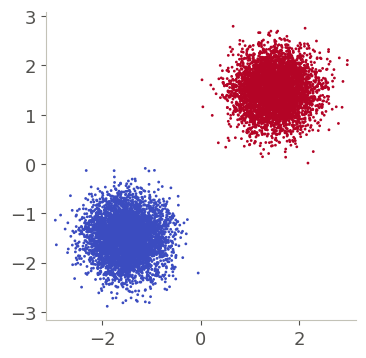

In [7]:
plt.figure(figsize=(4, 4))
plt.scatter(*X.T, c=y, s=1, cmap='coolwarm')
plt.axis('equal')
plt.show()

In [8]:
Xs, ys = spiral(stream(1, 1), **SPIRAL)
Xs.shape, np.bincount(ys), np.hypot(*Xs.T).max().round(2)

((10000, 2), array([5000, 5000], dtype=int64), 2.29)

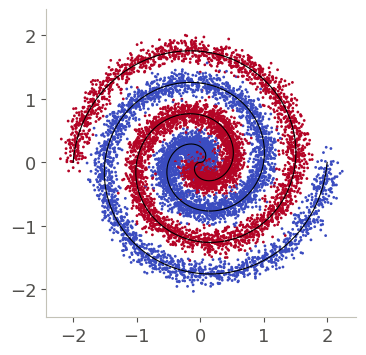

In [9]:
plt.figure(figsize=(4, 4))
plt.scatter(*Xs.T, c=ys, s=1, cmap='coolwarm')
for c in (0, 1):
    plt.plot(*arm(np.linspace(0, SPIRAL['K'], 500), c).T, 'k', lw=0.8)
plt.axis('equal')
plt.show()

In [10]:
d = pd.read_csv('data/spiral.csv')
d.head()

,x1,x2,y,split
0,-0.959530,0.972514,0,train
1,-0.956281,-0.674213,1,train
2,-0.793984,1.109425,0,test
3,0.565469,0.062279,1,train
4,0.010981,-0.789771,0,train


In [11]:
d.split.value_counts(), d.groupby('split').y.mean()

(split
 train    7000
 test     3000
 Name: count, dtype: int64,
 split
 test     0.5
 train    0.5
 Name: y, dtype: float64)

In [12]:
np.allclose(d[['x1', 'x2']].values, Xs), (d.y.values == ys).all()

(True, True)

In [13]:
Xtr, Xte, ytr, yte = load('linear')
Xtr.shape, Xte.shape, np.bincount(ytr), np.bincount(yte)

((7000, 2),
 (3000, 2),
 array([3500, 3500], dtype=int64),
 array([1500, 1500], dtype=int64))

In [14]:
p = Perceptron(random_state=SEED).fit(Xtr, ytr)
p.score(Xtr, ytr), p.score(Xte, yte), p.coef_, p.intercept_, p.n_iter_

(1.0, 1.0, array([[1.01636591, 1.20276181]]), array([1.]), 6)

In [15]:
perceptrons = [Perceptron(random_state=SEED + s).fit(Xtr, ytr) for s in range(20)]
pd.Series([m.score(Xte, yte) for m in perceptrons]).describe()

count    20.0
mean      1.0
std       0.0
min       1.0
25%       1.0
50%       1.0
75%       1.0
max       1.0
dtype: float64

In [16]:
def margin(m, X, y):
    w, b = m.coef_[0], m.intercept_[0]
    return np.min((2 * y - 1) * (X @ w + b)) / np.linalg.norm(w)


np.round(sorted(margin(m, Xtr, ytr) for m in perceptrons), 3)

array([0.06 , 0.067, 0.084, 0.12 , 0.123, 0.125, 0.129, 0.143, 0.18 ,
       0.202, 0.29 , 0.317, 0.343, 0.359, 0.36 , 0.539, 0.55 , 0.558,
       0.559, 0.561])

In [17]:
svm = SVC(kernel='linear', C=1).fit(Xtr, ytr)
svm.score(Xte, yte), svm.n_support_, round(margin(svm, Xtr, ytr), 3)

(1.0, array([2, 2]), 0.646)

In [18]:
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    s = SVC(kernel='linear', C=C).fit(Xtr, ytr)
    print(C, s.score(Xte, yte), s.n_support_.sum(), round(margin(s, Xtr, ytr), 3))

0.001 1.0 486 0.56
0.01 1.0 78 0.556


0.1 1.0 14 0.554
1 1.0 4 0.646
10 1.0 2 0.664
100 1.0 2 0.664


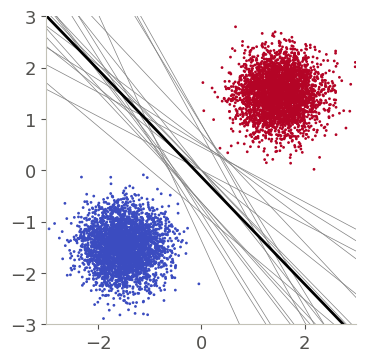

In [19]:
xs = np.array([-3, 3])
plt.figure(figsize=(4, 4))
plt.scatter(*Xtr.T, c=ytr, s=1, cmap='coolwarm')
for m in perceptrons:
    plt.plot(xs, -(m.intercept_[0] + m.coef_[0, 0] * xs) / m.coef_[0, 1], color='grey', lw=0.5)
plt.plot(xs, -(svm.intercept_[0] + svm.coef_[0, 0] * xs) / svm.coef_[0, 1], 'k', lw=2)
plt.xlim(-3, 3)
plt.ylim(-3, 3)
plt.show()

In [20]:
Xtr, Xte, ytr, yte = load('spiral')
accs = [Perceptron(random_state=SEED + s).fit(Xtr, ytr).score(Xte, yte) for s in range(20)]
svm = SVC(kernel='linear', C=1).fit(Xtr, ytr)
np.mean(accs).round(3), np.std(accs).round(3), min(accs), max(accs), svm.score(Xte, yte)

(0.514, 0.032, 0.4533333333333333, 0.5786666666666667, 0.531)

In [21]:
angles = np.linspace(0, np.pi, 7)
[(round(a, 2), round(np.mean(Xtr[ytr == 0] @ [np.cos(a), np.sin(a)] > 0), 3)) for a in angles]

[(0.0, 0.457),
 (0.52, 0.456),
 (1.05, 0.46),
 (1.57, 0.472),
 (2.09, 0.502),
 (2.62, 0.525),
 (3.14, 0.543)]

In [22]:
for g in [0.1, 1, 3, 10, 100, 1000]:
    t0 = time.time()
    m = SVC(kernel='rbf', gamma=g, C=1).fit(Xtr, ytr)
    print(g, round(m.score(Xtr, ytr), 4), round(m.score(Xte, yte), 4), m.n_support_.sum(), round(time.time() - t0, 1))

0.1 0.6436 0.6423 6110 45.8


1 0.864 0.8643 4520 36.2


3 0.96 0.961 1352 8.4


10 0.9641 0.9667 953 7.9


100 0.9684 0.9637 2155 12.6


1000 0.9781 0.9563 5435 35.6


In [23]:
for p in [2, 3, 5, 7, 9]:
    t0 = time.time()
    m = SVC(kernel='poly', degree=p, coef0=1, C=1).fit(Xtr, ytr)
    print(p, round(m.score(Xte, yte), 4), m.n_support_.sum(), round(time.time() - t0, 1))

2 0.5627 6260 5.9


3 0.6873 5435 11.0


5 0.707 4293 21.9


7 0.926 2072 6.4


9 0.9493 1260 5.0


In [24]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
for g in [1, 3, 10, 30]:
    for C in [1, 10]:
        print(g, C, cross_val_score(SVC(kernel='rbf', gamma=g, C=C), Xtr, ytr, cv=cv, n_jobs=4).mean().round(4))

1 1 0.8551


1 10 0.9257


3 1 0.9594


3 10 0.9613


10 1 0.9604


10 10 0.9591


30 1 0.9606


30 10 0.9581


In [25]:
for p in [5, 9, 13]:
    t0 = time.time()
    print(p, cross_val_score(SVC(kernel='poly', degree=p, coef0=1, C=10), Xtr, ytr, cv=cv, n_jobs=4).mean().round(4),
          round(time.time() - t0))

5 0.7159 58


9 0.9534 26


13 0.9571 591


In [26]:
rbf = SVC(kernel='rbf', gamma=3, C=10).fit(Xtr, ytr)
poly = SVC(kernel='poly', degree=13, coef0=1, C=10).fit(Xtr, ytr)
for name, m in [('rbf', rbf), ('poly', poly)]:
    s = m.decision_function(Xte)
    pred = (s > 0).astype(int)
    print(name, accuracy_score(yte, pred), round(f1_score(yte, pred), 3), round(roc_auc_score(yte, s), 3))
    print(confusion_matrix(yte, pred))

rbf 0.9656666666666667 0.965 0.993
[[1459   41]
 [  62 1438]]
poly 0.9606666666666667 0.961 0.991
[[1447   53]
 [  65 1435]]


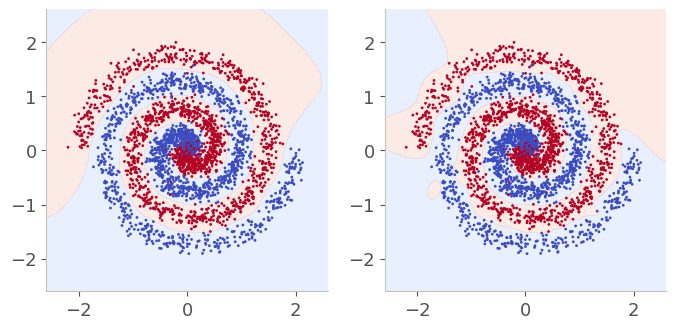

In [27]:
xx, yy = np.meshgrid(np.linspace(-2.6, 2.6, 200), np.linspace(-2.6, 2.6, 200))
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, m in zip(axes, [rbf, poly]):
    f = decision(m, np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, f > 0, alpha=0.2, cmap='coolwarm')
    ax.scatter(*Xte.T, c=yte, s=1, cmap='coolwarm')
    ax.set_aspect('equal')
plt.show()

In [28]:
Xa, ya = augment(Xtr, ytr, SD['low'], 200, stream(4, 1, 0))
Xa.shape, ya.shape, ya.mean().round(3)

((200, 1000, 2), (200, 1000), 0.5)

In [29]:
def aug_acc(m, X, y):
    return ((decision(m, X.reshape(-1, X.shape[-1])) > 0).reshape(y.shape) == y).mean(1)


for j, sd in enumerate([SD['low'], SD['high']]):
    Xa, ya = augment(Xtr, ytr, sd, 200, stream(4, 1, j))
    a = aug_acc(rbf, Xa, ya)
    print(sd, a.mean().round(4), a.std().round(4), a.min(), a.max())

0.05 0.9498 0.0066 0.931 0.965


0.25 0.675 0.0146 0.635 0.71


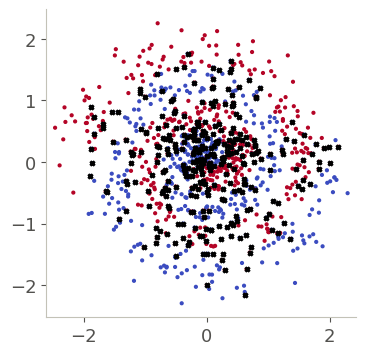

0.688

In [30]:
Xa, ya = augment(Xtr, ytr, SD['high'], 1, stream(4, 1, 1))
pred = decision(rbf, Xa[0]) > 0
plt.figure(figsize=(4, 4))
plt.scatter(*Xa[0].T, c=ya[0], s=4, cmap='coolwarm')
plt.scatter(*Xa[0][pred != ya[0]].T, marker='x', s=10, c='k')
plt.axis('equal')
plt.show()
(pred == ya[0]).mean()

In [31]:
over = SVC(kernel='rbf', gamma=1000, C=1000).fit(Xtr, ytr)
over.score(Xtr, ytr), over.score(Xte, yte), over.n_support_.sum()

(0.9941428571428571, 0.937, 5098)

In [32]:
sds = [0.01, 0.02, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.5, 1]
sweep = []
for j, sd in enumerate(sds):
    Xa, ya = augment(Xtr, ytr, sd, 40, stream(4, 1, 2, j))
    sweep.append({'sd': sd, 'best': aug_acc(rbf, Xa, ya).mean(), 'overfit': aug_acc(over, Xa, ya).mean()})
sweep = pd.DataFrame(sweep)
sweep.round(3)

,sd,best,overfit
0,0.01,0.964,0.971
1,0.02,0.963,0.959
2,0.05,0.949,0.932
3,0.10,0.900,0.867
4,0.15,0.821,0.786
5,0.20,0.741,0.707
6,0.25,0.672,0.636
7,0.30,0.622,0.585
8,0.50,0.548,0.520
9,1.00,0.525,0.503


In [33]:
crossing(sweep.sd.values, sweep.best.values, log=True), crossing(sweep.sd.values, sweep.overfit.values, log=True)

(0.2283698636536895, 0.20428271542594256)

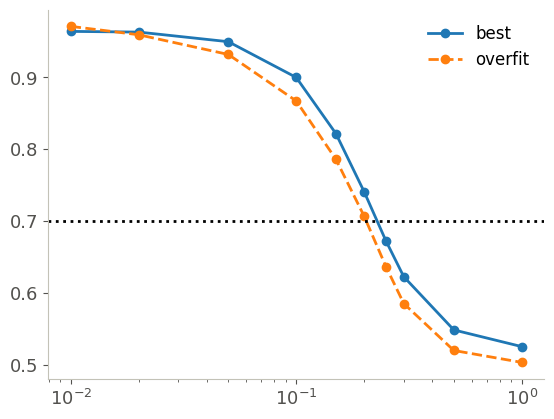

In [34]:
plt.semilogx(sweep.sd, sweep.best, 'o-', label='best')
plt.semilogx(sweep.sd, sweep.overfit, 'o--', label='overfit')
plt.axhline(0.7, color='k', ls=':')
plt.legend()
plt.show()

In [35]:
Xl, Xlte, yl, ylte = load('linear')
lin = SVC(kernel='linear', C=1).fit(Xl, yl)
[(sd, aug_acc(lin, *augment(Xl, yl, sd, 50, stream(4, 0, 9))).mean().round(4)) for sd in [0.25, 1, 2, 4]]

[(0.25, 1.0), (1, 0.9753), (2, 0.8491), (4, 0.6993)]

In [36]:
noisy = shuffle_labels(ytr, 50, stream(5, 1, 50, 0))
(noisy != ytr).mean(), np.bincount(noisy)

(0.24857142857142858, array([3500, 3500], dtype=int64))

In [37]:
rows = []
for p in [0, 15, 25, 50, 75, 90, 100]:
    noisy = shuffle_labels(ytr, p, stream(5, 1, p, 0))
    wrong = noisy != ytr
    m = SVC(kernel='rbf', gamma=3, C=10).fit(Xtr, noisy)
    fitted = (decision(m, Xtr) > 0) == noisy
    rows.append({'p': p, 'wrong': wrong.mean(), 'test': m.score(Xte, yte), 'fits_wrong': fitted[wrong].mean() if p else np.nan})
pd.DataFrame(rows).round(3)

,p,wrong,test,fits_wrong
0,0,0.000,0.966,NaN
1,15,0.077,0.967,0.050
2,25,0.130,0.966,0.038
3,50,0.249,0.964,0.043
4,75,0.378,0.960,0.052
5,90,0.447,0.854,0.167
6,100,0.501,0.494,0.542


In [38]:
rows = []
for p in [50, 90, 100]:
    for rep in range(2):
        noisy = shuffle_labels(yl, p, stream(5, 0, p, rep))
        rows.append({'p': p, 'rep': rep, 'wrong': (noisy != yl).mean(),
                     'test': SVC(kernel='linear', C=1).fit(Xl, noisy).score(Xlte, ylte)})
pd.DataFrame(rows).round(3)

,p,rep,wrong,test
0,50,0,0.252,1.000
1,50,1,0.254,1.000
2,90,0,0.455,1.000
3,90,1,0.456,1.000
4,100,0,0.500,0.809
5,100,1,0.497,1.000


In [39]:
rng = stream(6, 1, 15)
Xtr15, Xte15 = (np.c_[X, rng.normal(0, 0.1, (len(X), 13))] for X in (Xtr, Xte))
Xtr15.shape, Xte15.shape

((7000, 15), (3000, 15))

In [40]:
for g, C in [(3, 10), (10, 1), (10, 0.1)]:
    m = SVC(kernel='rbf', gamma=g, C=C).fit(Xtr15, ytr)
    print(g, C, m.score(Xte15, yte))

3 10 0.959


10 1 0.9646666666666667


10 0.1 0.9596666666666667


In [41]:
noisy = shuffle_labels(ytr, 75, stream(5, 1, 75, 0))
wrong = noisy != ytr
for A, B, g, C in [(Xtr, Xte, 3, 10), (Xtr15, Xte15, 10, 1)]:
    m = SVC(kernel='rbf', gamma=g, C=C).fit(A, noisy)
    print(A.shape[1], m.score(B, yte), ((decision(m, A) > 0) == noisy)[wrong].mean().round(3))

2 0.9596666666666667 0.052


15 0.805 0.78


In [42]:
for dim in [2, 5, 10, 15]:
    rng = stream(6, 1, dim)
    A, B = (np.c_[X, rng.normal(0, 0.1, (len(X), dim - 2))] for X in (Xtr, Xte))
    m = SVC(kernel='rbf', gamma=10, C=1).fit(A, noisy)
    print(dim, round(m.score(B, yte), 4))

2 0.924


5 0.8867


10 0.8253


15 0.805
